# BasicRecurrentLayer: A Small Tutorial

> **About this Python edition, version 1.0.0 (17 November 2026).** A port of the Wolfram notebook [`BasicRecurrentLayer-Tutorial.nb`](BasicRecurrentLayer-Tutorial.nb) to Python 3.14 with NumPy, Matplotlib and PyTorch. The text and the numbering of the sections are the same as in the Wolfram notebook; the code cells are numbered c.1, c.2, … in order. Wolfram's `BasicRecurrentLayer` corresponds to PyTorch's `nn.RNN`, with one difference in the biases that section 2 explains. Random numbers come from PyTorch and NumPy, so the random weights, the training data and the accuracy differ slightly from the Wolfram run; the text gives the values of the Python run.

*From the recurrence equation to a trained sequence classifier*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="28">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## 1. Mathematical formulation

A basic (Elman) recurrent layer reads a sequence of input vectors $x_1, \ldots, x_T$, with each $x_t \in \mathbb{R}^m$, and carries a hidden state $h_t \in \mathbb{R}^n$ forward in time. At every step the new state depends on the current input and the previous state:

$$
h_t = \sigma(W x_t + U h_{t-1} + b), \quad t = 1, \ldots, T, \quad h_0 = 0
$$

The ingredients:

- $W \in \mathbb{R}^{n \times m}$  input weights (Wolfram: array "InputWeights"; PyTorch: `weight_ih_l0`)
- $U \in \mathbb{R}^{n \times n}$  state (recurrent) weights (Wolfram: "StateWeights"; PyTorch: `weight_hh_l0`)
- $b \in \mathbb{R}^{n}$  biases (Wolfram: "Biases"; PyTorch: `bias_ih_l0 + bias_hh_l0`, see section 2)
- $\sigma$  elementwise activation: $\tanh$ by default, or ReLU $\max(0, z)$

The layer outputs the whole state sequence $(h_1, \ldots, h_T)$, a $T \times n$ matrix. The same W, U and b are reused at every step, so the number of parameters does not depend on the sequence length T:

$$
\#\text{params} = n m + n^2 + n = n (m + n + 1)
$$

Unrolling the recurrence shows that $h_t$ is a nested function of every earlier input, $h_3 = \sigma(W x_3 + U \sigma(W x_2 + U \sigma(W x_1 + b) + b) + b)$, which is what gives the layer memory. Training differentiates through this unrolled chain (backpropagation through time). Repeated multiplication by U is also why plain recurrent layers struggle with long-range dependencies (vanishing or exploding gradients); LongShortTermMemoryLayer and GatedRecurrentLayer (PyTorch: `nn.LSTM` and `nn.GRU`) were designed to address this.

## 2. Creating and inspecting the layer

PyTorch's `nn.RNN` computes $h_t = \sigma(W x_t + b_{ih} + U h_{t-1} + b_{hh})$: it has **two** bias vectors where the formula, and Wolfram's layer, have one. Only their sum $b = b_{ih} + b_{hh}$ matters, so the extra vector adds $n$ parameters that do nothing new. The helper `basic_recurrent_layer` below makes an `nn.RNN` and fixes $b_{hh} = 0$ (not trained), which gives exactly the layer of section 1, with $n(m + n + 1)$ trainable parameters.

`batch_first=True` means inputs are arrays of shape (batch, T, m); a single sequence is a batch of one.

A layer with state size n = 3 that reads sequences of any length whose elements are vectors of size m = 2:

In [1]:
# c.1
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.set_printoptions(precision=6, sci_mode=False)
np.set_printoptions(precision=6, suppress=True)

def basic_recurrent_layer(n, m, activation="tanh"):
    # the analogue of BasicRecurrentLayer[n, "Input" -> {"Varying", m}]:
    # nn.RNN with its second bias fixed at 0, so b = bias_ih_l0
    rnn = nn.RNN(input_size=m, hidden_size=n, nonlinearity=activation,
                 batch_first=True)
    with torch.no_grad():
        rnn.bias_hh_l0.zero_()
    rnn.bias_hh_l0.requires_grad_(False)
    return rnn

torch.manual_seed(1)
lay = basic_recurrent_layer(3, 2)
lay

RNN(2, 3, batch_first=True)

Apply it to a sequence of T = 3 vectors. The output is a 3 × 3 matrix: one state vector per time step. `nn.RNN` also returns the final state $h_T$, which section 4 uses.

In [2]:
# c.2
xs = torch.tensor([[1., 2.], [0.5, -1.], [-2., 0.]])
with torch.no_grad():
    out, hT = lay(xs[None])     # xs[None] is a batch of one sequence
out = out[0]
print(out)
print(out.shape)

tensor([[-0.258173,  0.472853,  0.145606],
        [ 0.487545, -0.144141, -0.656866],
        [-0.663992,  0.227241,  0.847626]])
torch.Size([3, 3])


Extract the learned arrays and check their shapes against the formulation above:

In [3]:
# c.3
w = lay.weight_ih_l0.detach().numpy()
u = lay.weight_hh_l0.detach().numpy()
b = (lay.bias_ih_l0 + lay.bias_hh_l0).detach().numpy()
{"W": w.shape, "U": u.shape, "b": b.shape}

{'W': (3, 2), 'U': (3, 3), 'b': (3,)}

Parameter count n(m + n + 1) = 3 × 6 = 18, counting the trainable arrays. A plain `nn.RNN(2, 3)` would report 21, the 3 extra being $b_{hh}$:

In [4]:
# c.4
print(sum(p.numel() for p in lay.parameters() if p.requires_grad))
print(sum(p.numel() for p in nn.RNN(2, 3).parameters()))

18
21


## 3. Verifying the recurrence by hand

The recurrence is a left fold over the sequence, starting from $h_0 = 0$. A loop over the sequence keeps every intermediate state, like FoldList; the list starts at $h_1$, so nothing needs dropping.

In [5]:
# c.5
def step(h, x):
    return np.tanh(w @ x + u @ h + b)

h = np.zeros(3)
manual = []
for x in xs.numpy():
    h = step(h, x)
    manual.append(h)
manual = np.array(manual)
manual

array([[-0.258173,  0.472853,  0.145606],
       [ 0.487545, -0.144141, -0.656866],
       [-0.663991,  0.227241,  0.847626]])

The difference from the layer's output is at the level of single-precision rounding (about $10^{-8}$; PyTorch computes in float32, the hand check in float64):

In [6]:
# c.6
np.abs(out.numpy() - manual).max()

np.float64(3.6237880418621415e-08)

## 4. Carrying the state across calls

Each ordinary call starts again from the zero state. Wolfram's NetStateObject keeps the final state between calls; in PyTorch we keep it ourselves, passing the returned state back in as the second argument. Feeding the sequence one step at a time gives the same result as feeding it all at once:

In [7]:
# c.7
state = None                     # None means h0 = 0
stepwise = []
with torch.no_grad():
    for x in xs:
        o, state = lay(x[None, None], state)   # a batch of one sequence of length 1
        stepwise.append(o[0, 0])
stepwise = torch.stack(stepwise)
(stepwise - out).abs().max().item()

0.0

## 5. Options

- The activation (`nonlinearity` in PyTorch) accepts `"tanh"` (the default) or `"relu"`. Other functions are rejected with an error, as Wolfram rejects them with a message.
- Wolfram's "Dropout" option applies dropout regularization inside the recurrent layer during training. PyTorch's `nn.RNN(..., dropout=p)` only drops out between stacked layers, so with one layer it does nothing and gives a warning; the nearest thing is an `nn.Dropout(0.2)` on the input sequence (used in training mode only).

In [8]:
# c.8
import warnings

relu_layer = basic_recurrent_layer(3, 2, activation="relu")
print(relu_layer, "nonlinearity:", relu_layer.nonlinearity)

try:
    nn.RNN(2, 3, nonlinearity="sigmoid")
except ValueError as e:
    print("ValueError:", e)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    nn.RNN(2, 3, dropout=0.2)
print("UserWarning:", caught[0].message)

nn.Sequential(nn.Dropout(0.2), relu_layer)

RNN(2, 3, batch_first=True) nonlinearity: relu
ValueError: Unknown nonlinearity 'sigmoid'. Select from 'tanh' or 'relu'.


Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): RNN(2, 3, batch_first=True)
)

## 6. Example: is the sequence going up or down?

Generate random scalar sequences of length 3 to 8. A sequence is labeled "Up" if its last value is larger than its first. The network has to remember the first element until the end, so it needs the recurrent state.

In [9]:
# c.9
rng = np.random.default_rng(42)
classes = ["Down", "Up"]

def gen(k, lengths=(3, 8)):
    data = []
    for _ in range(k):
        s = rng.uniform(-1, 1, rng.integers(lengths[0], lengths[1] + 1))
        data.append((s[:, None].astype(np.float32), int(s[-1] > s[0])))
    return data

train = gen(2000)
test = gen(200)
for i in rng.choice(len(train), 3, replace=False):
    s, label = train[i]
    print(np.round(s.ravel(), 3), "->", classes[label])

[-0.659 -0.058  0.701  0.93   0.19 ] -> Up
[-0.078 -0.838 -0.968 -0.046 -0.011 -0.185] -> Down
[0.356 0.581 0.7  ] -> Up


The recurrent layer reads the sequence; the final state $h_T$ (Wolfram: SequenceLastLayer) goes to a linear layer and softmax, which turn it into class probabilities.

The sequences have different lengths. To train on a batch at once, PyTorch pads them to the same length and *packs* them (`pack_padded_sequence`), so the layer stops at each sequence's true end and returns the right $h_T$ for each one. The softmax is folded into the loss: `nn.CrossEntropyLoss` takes the linear layer's outputs and applies softmax and the log-loss together.

In [10]:
# c.10
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

class Classifier(nn.Module):
    def __init__(self, n=16):
        super().__init__()
        self.rnn = basic_recurrent_layer(n, 1)
        self.linear = nn.Linear(n, 2)

    def forward(self, seqs):
        # seqs: a list of arrays of shape (T_i, 1)
        lengths = torch.tensor([len(s) for s in seqs])
        padded = pad_sequence([torch.as_tensor(s) for s in seqs], batch_first=True)
        packed = pack_padded_sequence(padded, lengths, batch_first=True,
                                      enforce_sorted=False)
        _, hT = self.rnn(packed)        # hT has shape (1, batch, n): the last state
        return self.linear(hT[0])       # scores; softmax gives the probabilities

    def probabilities(self, seqs):
        with torch.no_grad():
            return torch.softmax(self(seqs), dim=1)

    def classify(self, seqs):
        return [classes[i] for i in self.probabilities(seqs).argmax(1)]

torch.manual_seed(3)
net = Classifier()
net

Classifier(
  (rnn): RNN(1, 16, batch_first=True)
  (linear): Linear(in_features=16, out_features=2, bias=True)
)

Train for 15 rounds (epochs) with Adam and batches of 64, the defaults of NetTrain:

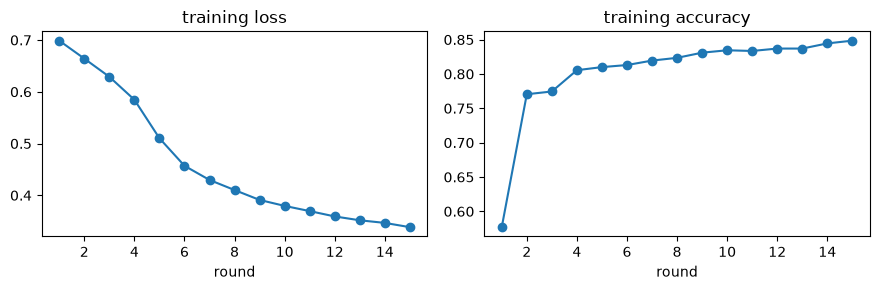

In [11]:
# c.11
def accuracy(model, data):
    pred = model.probabilities([s for s, _ in data]).argmax(1)
    return (pred == torch.tensor([y for _, y in data])).float().mean().item()

def net_train(model, data, rounds=15, batch=64, lr=1e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss()
    history = []
    for r in range(rounds):
        total = 0.0
        for idx in torch.randperm(len(data), generator=g).split(batch):
            seqs = [data[i][0] for i in idx]
            ys = torch.tensor([data[i][1] for i in idx])
            loss = lossf(model(seqs), ys)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        history.append((total / len(data), accuracy(model, data)))
    return history

history = net_train(net, train)
loss, acc = np.array(history).T
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3))
a1.plot(range(1, 16), loss, "o-"); a1.set(xlabel="round", title="training loss")
a2.plot(range(1, 16), acc, "o-"); a2.set(xlabel="round", title="training accuracy")
fig.tight_layout()
plt.show()

Accuracy on held-out sequences (0.805 after 15 rounds in this run; around 0.85 in the Wolfram run; more rounds help):

In [12]:
# c.12
round(accuracy(net, test), 3)

0.805

Try it on new sequences:

In [13]:
# c.13
new = [np.array([[-0.9], [0.3], [0.1], [0.7]], dtype=np.float32),
       np.array([[0.8], [-0.2], [0.5], [-0.6]], dtype=np.float32)]
print(net.classify(new))
print(net.probabilities(new))

['Up', 'Down']
tensor([[0.027534, 0.972466],
        [0.939702, 0.060298]])


## 7. Exercises

- Switch the activation to `"relu"` and redo the hand check of section 3 using `np.maximum(0, z)` in place of `np.tanh`.
- Train the classifier on sequences of length 3 to 8, then test it on sequences of length 30 (`gen(200, lengths=(30, 30))`). How does accuracy change, and why?
- Replace the recurrent layer with `nn.LSTM(1, 16, batch_first=True)` (the LongShortTermMemoryLayer) and compare accuracy on long sequences. Note that `nn.LSTM` returns `(hT, cT)` as its state.
- Show that the parameter count stays 18 whatever sequence length you feed the layer from section 2.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>